# Preparación para LSTM - TIBAITATA
## 1. Análisis de continuidad temporal

**Objetivo.** Determinar si la serie diaria de la estación Tibaitatá (2005-2022) es continua o si le faltan **días completos**. Una LSTM construye ventanas de días consecutivos, así que cualquier hueco en el calendario afecta directamente cómo se pueden armar esas ventanas.

**Alcance y restricciones de este análisis**
- Es de solo lectura: no se imputa, no se elimina ningún registro y no se modifica el dataset original (`df_original`).
- Los registros existentes se toman como están. No se revisan valores nulos dentro de ellos. Solo se pregunta si existe o no una fila para cada día del calendario.
- Todas las transformaciones (conversión de fechas, orden) se hacen sobre copias nuevas.

## 1.1 Importaciones y configuración

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUTA_DATASET = "./Datasets/Tibaitata_ET0_FAO56.pkl"   # salida del notebook 04
COLUMNA_FECHA = "Fecha"

pd.set_option("display.width", 120)
pd.set_option("display.max_rows", 100)

## 1.2 Carga del dataset original

Se carga el dataset consolidado y se guarda una **copia de control** (`_snapshot_original`). Esa copia se usa solo al final para comprobar que el dataset original no cambió durante el análisis.

In [15]:
df_original = pd.read_pickle(RUTA_DATASET)
_snapshot_original = df_original.copy(deep=True)   # solo para la verificación final

print(f"Dimensiones del dataset original: {df_original.shape[0]} filas x {df_original.shape[1]} columnas")
print(f"Tipo actual de '{COLUMNA_FECHA}': {df_original[COLUMNA_FECHA].dtype}")
df_original[[COLUMNA_FECHA]].head()

Dimensiones del dataset original: 2909 filas x 33 columnas
Tipo actual de 'Fecha': datetime64[us]


,Fecha
0,2005-02-02
1,2005-02-03
2,2005-02-04
3,2005-02-05
4,2005-02-06


## 1.3 Conversión de `Fecha` a datetime y orden cronológico

**Procedimiento**
1. Se convierte `Fecha` con `pd.to_datetime(..., errors="coerce")`. Si algún valor no se puede interpretar queda como `NaT` y se reporta, pero la fila no se elimina.
2. Se crea `df_ordenado`, una copia del dataset con `Fecha` convertida y ordenada de menor a mayor. `df_original` queda intacto.
3. Se revisa si las fechas traen componente horaria. El calendario es diario a las 00:00, así que una hora distinta de cero haría que un día existente parezca ausente.

**Cómo leer el resultado.** Lo esperado es 0 fechas no interpretables y 0 con hora. El orden original puede ya ser cronológico, y entonces el ordenamiento no cambia nada.

In [16]:
# 1) Conversión a datetime (sobre una Serie nueva; no se toca df_original)
fechas_convertidas = pd.to_datetime(df_original[COLUMNA_FECHA], errors="coerce")

n_no_interpretables = int(fechas_convertidas.isna().sum())
n_con_hora = int((fechas_convertidas.dropna() != fechas_convertidas.dropna().dt.normalize()).sum())
ya_estaba_ordenado = bool(fechas_convertidas.is_monotonic_increasing)

# 2) Copia ordenada cronológicamente (conserva todas las filas y columnas)
df_ordenado = (
    df_original
    .assign(**{COLUMNA_FECHA: fechas_convertidas})
    .sort_values(COLUMNA_FECHA, kind="stable")
    .reset_index(drop=True)
)

print(f"Tipo de '{COLUMNA_FECHA}' tras la conversión: {df_ordenado[COLUMNA_FECHA].dtype}")
print(f"Fechas no interpretables (NaT):        {n_no_interpretables}")
print(f"Fechas con componente horaria != 00:00: {n_con_hora}")
print(f"Ya estaban en orden cronológico:        {ya_estaba_ordenado}")
print(f"Filas antes / después de ordenar:       {len(df_original)} / {len(df_ordenado)}")

Tipo de 'Fecha' tras la conversión: datetime64[us]
Fechas no interpretables (NaT):        0
Fechas con componente horaria != 00:00: 0
Ya estaban en orden cronológico:        True
Filas antes / después de ordenar:       2909 / 2909


## 1.4 Fecha inicial, fecha final y número de registros

**Procedimiento.** Se toman `min` y `max` de `Fecha` para delimitar la serie. Se cuentan:
- los **registros** (filas del dataset),
- las **fechas únicas** (días distintos con información),
- las **fechas duplicadas** (filas que repiten un día ya presente).

**Por qué importa separar registros de fechas únicas.** El porcentaje de días faltantes se calcula contra días del calendario. Si hubiera fechas repetidas, contar filas en lugar de fechas únicas subestimaría los días ausentes. Si las duplicadas son 0, registros y fechas únicas coinciden.

In [17]:
fechas = df_ordenado[COLUMNA_FECHA].dropna()          # Serie derivada; df_ordenado conserva todas las filas
fechas_unicas = pd.DatetimeIndex(fechas.dt.normalize().unique()).sort_values()

fecha_inicial = fechas_unicas.min()
fecha_final = fechas_unicas.max()

n_registros = len(df_original)
n_fechas_unicas = len(fechas_unicas)
n_duplicadas = int(fechas.duplicated().sum())

print(f"Fecha inicial:      {fecha_inicial.date()}")
print(f"Fecha final:        {fecha_final.date()}")
print(f"Registros (filas):  {n_registros}")
print(f"Fechas únicas:      {n_fechas_unicas}")
print(f"Fechas duplicadas:  {n_duplicadas}")

Fecha inicial:      2005-02-02
Fecha final:        2022-10-31
Registros (filas):  2909
Fechas únicas:      2909
Fechas duplicadas:  0


## 1.5 Calendario diario completo

**Procedimiento.** `pd.date_range(inicio, fin, freq="D")` genera todos los días entre la fecha inicial y la final, ambas incluidas. Ese calendario es la referencia de lo que debería existir si la serie fuera continua.

In [18]:
calendario_completo = pd.date_range(start=fecha_inicial, end=fecha_final, freq="D")
n_dias_esperados = len(calendario_completo)

print(f"Calendario: {calendario_completo[0].date()} -> {calendario_completo[-1].date()}")
print(f"Días esperados (calendario completo): {n_dias_esperados}")

Calendario: 2005-02-02 -> 2022-10-31
Días esperados (calendario completo): 6481


## 1.6 Fechas ausentes

**Procedimiento.** Se calcula la diferencia de conjuntos entre el calendario completo y las fechas existentes (`calendario_completo.difference(fechas_unicas)`). El resultado son los días del calendario para los que **no existe ninguna fila** en el dataset.

Se agrega una verificación de consistencia: días esperados = días presentes + días ausentes.

In [19]:
fechas_faltantes = calendario_completo.difference(fechas_unicas)

n_dias_faltantes = len(fechas_faltantes)
n_dias_presentes = n_dias_esperados - n_dias_faltantes

assert n_dias_presentes == n_fechas_unicas, "Inconsistencia: presentes != fechas únicas"

print(f"Días faltantes: {n_dias_faltantes}")
print("Primeras 10 fechas ausentes:", [d.date().isoformat() for d in fechas_faltantes[:10]])
print("Últimas 10 fechas ausentes: ", [d.date().isoformat() for d in fechas_faltantes[-10:]])

Días faltantes: 3572
Primeras 10 fechas ausentes: ['2005-02-11', '2005-02-13', '2005-03-09', '2005-03-10', '2005-03-12', '2005-03-20', '2005-03-21', '2005-03-22', '2005-03-24', '2005-03-26']
Últimas 10 fechas ausentes:  ['2022-01-30', '2022-01-31', '2022-02-01', '2022-02-02', '2022-02-16', '2022-02-17', '2022-02-18', '2022-02-19', '2022-02-20', '2022-04-22']


## 1.7 Número y porcentaje de días faltantes

**Procedimiento.** Porcentaje de faltantes = `días faltantes / días esperados * 100`. También se muestra el complemento (cobertura), que es el porcentaje del calendario que sí tiene registro.

**Cómo leer el resultado.** La cobertura indica qué parte del periodo 2005-2022 tiene información disponible. Un porcentaje alto de faltantes limita la cantidad de ventanas consecutivas que se pueden formar para la LSTM.

In [20]:
pct_faltantes = n_dias_faltantes / n_dias_esperados * 100
pct_cobertura = n_dias_presentes / n_dias_esperados * 100

print(f"Días esperados:   {n_dias_esperados}")
print(f"Días presentes:   {n_dias_presentes}  ({pct_cobertura:.2f} %)")
print(f"Días faltantes:   {n_dias_faltantes}  ({pct_faltantes:.2f} %)")

Días esperados:   6481
Días presentes:   2909  (44.89 %)
Días faltantes:   3572  (55.11 %)


## 1.8 Distribución de los faltantes: tramos consecutivos y por año

Saber cuántos días faltan no basta para una serie temporal. Importa **cómo** se agrupan:
- **Tramos consecutivos**: días ausentes seguidos forman un hueco. Se reporta inicio, fin y duración de cada uno.
- **Por año**: cuántos días esperados y ausentes tiene cada año.

**Cómo leer el resultado.** Pocos huecos largos indican que la serie está partida en bloques continuos. Muchos huecos cortos indican fallas esporádicas. Un año con casi todos sus días ausentes indica un periodo sin datos.

In [21]:
# --- Tramos consecutivos de días ausentes ---
if n_dias_faltantes > 0:
    s_falt = pd.Series(fechas_faltantes)
    id_tramo = (s_falt.diff() != pd.Timedelta(days=1)).cumsum()
    tramos_faltantes = (
        s_falt.groupby(id_tramo)
        .agg(inicio="min", fin="max", dias="count")
        .reset_index(drop=True)
    )
    tramos_faltantes.index = tramos_faltantes.index + 1
    tramos_faltantes.index.name = "tramo"
else:
    tramos_faltantes = pd.DataFrame(columns=["inicio", "fin", "dias"])

print(f"Tramos (huecos) de días ausentes consecutivos: {len(tramos_faltantes)}")
if len(tramos_faltantes):
    print(f"Hueco más largo: {int(tramos_faltantes['dias'].max())} días")
    print(f"Hueco más corto: {int(tramos_faltantes['dias'].min())} días")
    print(f"Huecos de 1 día: {int((tramos_faltantes['dias'] == 1).sum())}")
tramos_faltantes

Tramos (huecos) de días ausentes consecutivos: 230
Hueco más largo: 1789 días
Hueco más corto: 1 días
Huecos de 1 día: 128


,inicio,fin,dias
tramo,,,
1,2005-02-11,2005-02-11,1
2,2005-02-13,2005-02-13,1
3,2005-03-09,2005-03-10,2
4,2005-03-12,2005-03-12,1
5,2005-03-20,2005-03-22,3
...,...,...,...
226,2021-08-24,2021-08-29,6
227,2021-11-01,2021-11-01,1
228,2022-01-03,2022-02-02,31


In [22]:
# --- Resumen por año ---
esperados_anio = pd.Series(1, index=calendario_completo).groupby(calendario_completo.year).sum()
faltantes_anio = pd.Series(1, index=fechas_faltantes).groupby(fechas_faltantes.year).sum()

resumen_anual = pd.DataFrame({"dias_esperados": esperados_anio, "dias_faltantes": faltantes_anio})
resumen_anual["dias_faltantes"] = resumen_anual["dias_faltantes"].fillna(0).astype(int)
resumen_anual["dias_presentes"] = resumen_anual["dias_esperados"] - resumen_anual["dias_faltantes"]
resumen_anual["pct_faltantes"] = (resumen_anual["dias_faltantes"] / resumen_anual["dias_esperados"] * 100).round(2)
resumen_anual.index.name = "anio"
resumen_anual

,dias_esperados,dias_faltantes,dias_presentes,pct_faltantes
anio,,,,
2005,333,66,267,19.82
2006,365,330,35,90.41
2007,365,365,0,100.00
2008,366,366,0,100.00
2009,365,365,0,100.00
2010,365,364,1,99.73
2011,365,247,118,67.67
2012,366,190,176,51.91
2013,365,227,138,62.19


## 1.9 Visualización

**Figura 1. Línea de tiempo de disponibilidad.** Cada franja roja es un tramo de días ausentes. Las zonas sin franja tienen registro diario.

**Figura 2. Días presentes y faltantes por año.** Permite comparar la cobertura entre años.

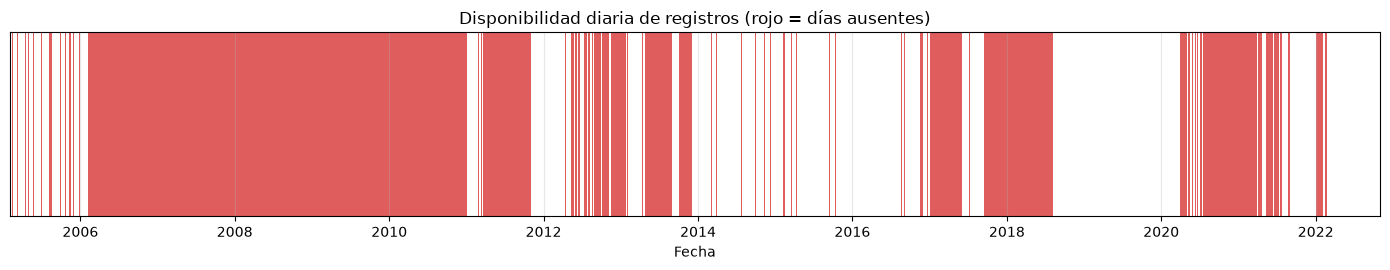

In [23]:
fig, ax = plt.subplots(figsize=(14, 2.8))

for fila in tramos_faltantes.itertuples():
    ax.axvspan(fila.inicio, fila.fin + pd.Timedelta(days=1), color="tab:red", alpha=0.75, lw=0)

ax.set_xlim(calendario_completo[0], calendario_completo[-1] + pd.Timedelta(days=1))
ax.set_yticks([])
ax.set_xlabel("Fecha")
ax.set_title("Disponibilidad diaria de registros (rojo = días ausentes)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

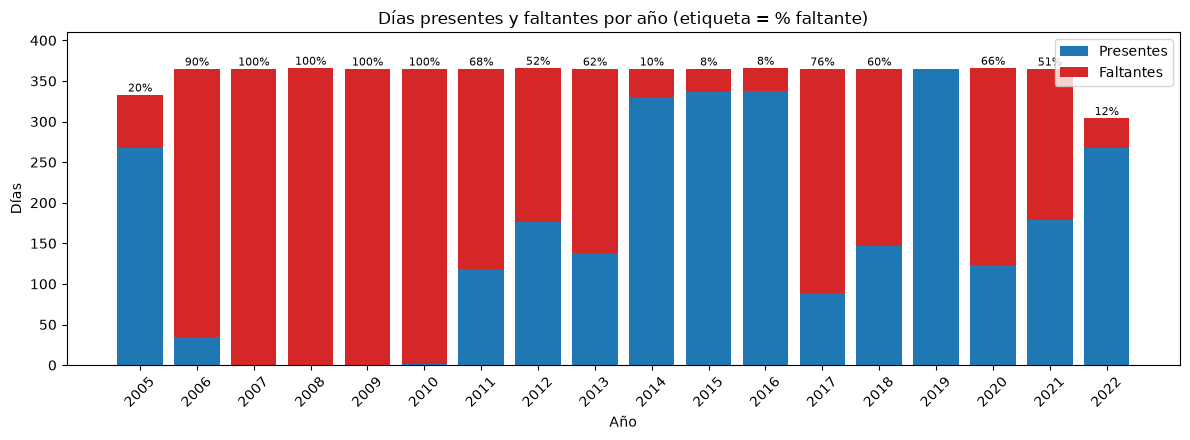

In [24]:
fig, ax = plt.subplots(figsize=(12, 4.5))

ax.bar(resumen_anual.index, resumen_anual["dias_presentes"], label="Presentes", color="tab:blue")
ax.bar(resumen_anual.index, resumen_anual["dias_faltantes"], bottom=resumen_anual["dias_presentes"],
       label="Faltantes", color="tab:red")

for anio, fila in resumen_anual.iterrows():
    if fila["dias_faltantes"] > 0:
        ax.text(anio, fila["dias_esperados"] + 4, f"{fila['pct_faltantes']:.0f}%", ha="center", fontsize=8)

ax.set_xticks(resumen_anual.index)
ax.set_xticklabels(resumen_anual.index, rotation=45)
ax.set_ylabel("Días")
ax.set_xlabel("Año")
ax.set_title("Días presentes y faltantes por año (etiqueta = % faltante)")
ax.set_ylim(0, resumen_anual["dias_esperados"].max() * 1.12)
ax.legend()
plt.tight_layout()
plt.show()

## 1.10 Resumen general de continuidad temporal

Tabla única con los indicadores de las secciones anteriores.

In [25]:
resumen_continuidad = pd.Series(
    {
        "Fecha inicial": fecha_inicial.date().isoformat(),
        "Fecha final": fecha_final.date().isoformat(),
        "Registros existentes (filas)": n_registros,
        "Fechas únicas con registro": n_fechas_unicas,
        "Fechas duplicadas": n_duplicadas,
        "Días esperados (calendario completo)": n_dias_esperados,
        "Días faltantes": n_dias_faltantes,
        "% días faltantes": round(pct_faltantes, 2),
        "% cobertura": round(pct_cobertura, 2),
        "Tramos de días ausentes": len(tramos_faltantes),
        "Hueco más largo (días)": int(tramos_faltantes["dias"].max()) if len(tramos_faltantes) else 0,
        "¿Serie continua?": "Sí" if n_dias_faltantes == 0 else "No",
    },
    name="Valor",
).to_frame()
resumen_continuidad

,Valor
Fecha inicial,2005-02-02
Fecha final,2022-10-31
Registros existentes (filas),2909
Fechas únicas con registro,2909
Fechas duplicadas,0
Días esperados (calendario completo),6481
Días faltantes,3572
% días faltantes,55.11
% cobertura,44.89
Tramos de días ausentes,230


**Interpretación**
- Si `¿Serie continua?` es "No", la serie tiene días completos sin registro. Ese resultado se documenta tal cual: este análisis no los rellena.
- Una LSTM necesita ventanas de días consecutivos. Los tramos de la sección 1.8 marcan los puntos donde una ventana no puede cruzar. La decisión sobre cómo construir las ventanas (por ejemplo, solo con bloques continuos de longitud suficiente) corresponde al paso siguiente y se toma con esta información.

## 1.11 Verificación: el dataset original no se modificó

Se compara `df_original` con la copia de control creada en 1.2.

In [26]:
assert df_original.equals(_snapshot_original), "df_original fue modificado"
assert df_original.shape == _snapshot_original.shape
assert len(df_ordenado) == len(df_original), "Se perdieron o agregaron filas al ordenar"

print("OK: df_original sin cambios (mismos valores, columnas y tipos).")
print(f"OK: df_ordenado conserva las {len(df_ordenado)} filas del original.")

OK: df_original sin cambios (mismos valores, columnas y tipos).
OK: df_ordenado conserva las 2909 filas del original.


# 2. Intervalos de fechas faltantes

**Objetivo.** Convertir la lista de días ausentes (sección 1.6) en **intervalos**: bloques de días ausentes que se suceden uno tras otro sin ningún día con registro en medio. Cada intervalo se describe con su fecha inicial, su fecha final y su duración en días.

**Regla de consecutividad.** Dos fechas ausentes pertenecen al mismo intervalo solo si están separadas **exactamente 1 día**. Si entre ellas hay uno o más días con registro, la diferencia es de 2 días o más y pertenecen a intervalos distintos.

**Alcance.** Igual que en la sección 1, es de solo lectura: no se rellenan fechas, no se eliminan registros y no se modifica `df_original`. Se parte de `fechas_faltantes` (sección 1.6) y todo lo nuevo se guarda en objetos nuevos.

## 2.1 DataFrame exclusivo con las fechas faltantes

**Procedimiento.** Se construye un DataFrame de una columna con las fechas de `fechas_faltantes`, ordenadas de menor a mayor. Se comprueba que el conteo coincide con la sección 1.6 y que ninguna de estas fechas existe en el dataset.

In [27]:
df_faltantes = (
    pd.DataFrame({"fecha_faltante": pd.DatetimeIndex(fechas_faltantes)})
    .sort_values("fecha_faltante")
    .reset_index(drop=True)
)

# Comprobaciones: mismo conteo que en 1.6, sin repetidas y ninguna presente en el dataset
assert len(df_faltantes) == n_dias_faltantes
assert df_faltantes["fecha_faltante"].is_unique
assert not df_faltantes["fecha_faltante"].isin(fechas_unicas).any()

print(f"Fechas faltantes: {len(df_faltantes)}")
df_faltantes.head(10)

Fechas faltantes: 3572


,fecha_faltante
0,2005-02-11
1,2005-02-13
2,2005-03-09
3,2005-03-10
4,2005-03-12
5,2005-03-20
6,2005-03-21
7,2005-03-22
8,2005-03-24
9,2005-03-26


## 2.2 Identificación de fechas consecutivas

**Procedimiento.**
1. `dif_dias`: días transcurridos desde la fecha ausente anterior (`diff()`). La primera fila no tiene anterior y queda en `NaN`.
2. `es_consecutiva`: `True` solo cuando `dif_dias == 1`. Una diferencia de 2 o más significa que entre ambas fechas hay al menos un día con registro, y por lo tanto no son consecutivas.
3. `id_intervalo`: cada fecha que **no** es consecutiva de la anterior abre un intervalo nuevo. La suma acumulada (`cumsum`) de esas aperturas numera los intervalos.

In [28]:
df_faltantes["dif_dias"] = df_faltantes["fecha_faltante"].diff().dt.days
df_faltantes["es_consecutiva"] = df_faltantes["dif_dias"].eq(1)            # NaN (primera fila) -> False
df_faltantes["id_intervalo"] = (~df_faltantes["es_consecutiva"]).cumsum()   # 1, 2, 3, ...

print(f"Fechas que continúan el intervalo anterior: {int(df_faltantes['es_consecutiva'].sum())}")
print(f"Fechas que abren un intervalo nuevo:       {int((~df_faltantes['es_consecutiva']).sum())}")
df_faltantes.head(12)

Fechas que continúan el intervalo anterior: 3342
Fechas que abren un intervalo nuevo:       230


,fecha_faltante,dif_dias,es_consecutiva,id_intervalo
0,2005-02-11,NaN,False,1
1,2005-02-13,2.0,False,2
2,2005-03-09,24.0,False,3
3,2005-03-10,1.0,True,3
4,2005-03-12,2.0,False,4
5,2005-03-20,8.0,False,5
6,2005-03-21,1.0,True,5
7,2005-03-22,1.0,True,5
8,2005-03-24,2.0,False,6
9,2005-03-26,2.0,False,7


## 2.3 Agrupación en intervalos

**Procedimiento.** Se agrupa por `id_intervalo` y se calcula, para cada grupo:
- `fecha_inicial`: primera fecha ausente del intervalo.
- `fecha_final`: última fecha ausente del intervalo.
- `dias_faltantes`: cantidad de fechas ausentes del intervalo.

Los intervalos se ordenan por `fecha_inicial` y se numeran de 1 en adelante en ese orden.

**Verificaciones.**
- `dias_faltantes` debe ser igual a `(fecha_final - fecha_inicial) + 1`. Si lo es, el intervalo no contiene ningún día con registro en medio.
- Entre el final de un intervalo y el inicio del siguiente debe haber al menos 1 día con registro.
- La suma de `dias_faltantes` debe ser igual al total de días faltantes de la sección 1.6.

In [29]:
intervalos_faltantes = (
    df_faltantes
    .groupby("id_intervalo")["fecha_faltante"]
    .agg(fecha_inicial="min", fecha_final="max", dias_faltantes="count")
    .sort_values("fecha_inicial")
    .reset_index(drop=True)
)
intervalos_faltantes.index = intervalos_faltantes.index + 1
intervalos_faltantes.index.name = "intervalo"

# 1) Sin huecos internos: días contados == días entre inicio y fin (ambos incluidos)
dias_calendario = (intervalos_faltantes["fecha_final"] - intervalos_faltantes["fecha_inicial"]).dt.days + 1
assert (intervalos_faltantes["dias_faltantes"] == dias_calendario).all(), "Un intervalo contiene días con registro"

# 2) Separación entre intervalos: al menos 1 día con registro entre uno y el siguiente
dias_con_registro_entre = (
    intervalos_faltantes["fecha_inicial"].shift(-1) - intervalos_faltantes["fecha_final"]
).dt.days - 1
assert (dias_con_registro_entre.dropna() >= 1).all(), "Hay intervalos contiguos sin separar"

# 3) Totales
assert intervalos_faltantes["dias_faltantes"].sum() == n_dias_faltantes

print(f"Intervalos: {len(intervalos_faltantes)} | días faltantes acumulados: {intervalos_faltantes['dias_faltantes'].sum()}")
intervalos_faltantes

Intervalos: 230 | días faltantes acumulados: 3572


,fecha_inicial,fecha_final,dias_faltantes
intervalo,,,
1,2005-02-11,2005-02-11,1
2,2005-02-13,2005-02-13,1
3,2005-03-09,2005-03-10,2
4,2005-03-12,2005-03-12,1
5,2005-03-20,2005-03-22,3
...,...,...,...
226,2021-08-24,2021-08-29,6
227,2021-11-01,2021-11-01,1
228,2022-01-03,2022-02-02,31


## 2.4 Estadísticas de duración de los intervalos

**Procedimiento.** Se resumen las duraciones (`dias_faltantes`) de todos los intervalos: cantidad, media, máximo, mínimo y mediana.

**Cómo leer el resultado.** Una media mucho mayor que la mediana indica que unos pocos intervalos muy largos concentran buena parte de los días faltantes, mientras que la mayoría de los intervalos es corta. Por eso se reportan ambas.

In [30]:
dur = intervalos_faltantes["dias_faltantes"]

estadisticas_intervalos = pd.Series(
    {
        "Cantidad de intervalos": int(dur.count()),
        "Duración promedio (días)": round(float(dur.mean()), 2),
        "Duración máxima (días)": int(dur.max()),
        "Duración mínima (días)": int(dur.min()),
        "Mediana de duración (días)": float(dur.median()),
    },
    name="Valor",
    dtype=object,
).to_frame()
estadisticas_intervalos

,Valor
Cantidad de intervalos,230
Duración promedio (días),15.53
Duración máxima (días),1789
Duración mínima (días),1
Mediana de duración (días),1.0


## 2.5 Intervalos más largos

**Procedimiento.** Se ordenan los intervalos por duración descendente (desempate por fecha inicial) y se muestran los `N_TOP` primeros. La columna `intervalo` conserva el número cronológico de la tabla 2.3 para poder ubicarlos. Se agregan:
- `pct_del_total_faltante`: peso del intervalo sobre todos los días faltantes.
- `pct_acumulado`: suma de ese peso hasta el intervalo de la fila.

In [31]:
N_TOP = 10

intervalos_mas_largos = (
    intervalos_faltantes
    .sort_values(["dias_faltantes", "fecha_inicial"], ascending=[False, True])
    .head(N_TOP)
    .copy()
)
intervalos_mas_largos["pct_del_total_faltante"] = (intervalos_mas_largos["dias_faltantes"] / n_dias_faltantes * 100).round(2)
intervalos_mas_largos["pct_acumulado"] = intervalos_mas_largos["pct_del_total_faltante"].cumsum().round(2)

intervalos_mas_largos

,fecha_inicial,fecha_final,dias_faltantes,pct_del_total_faltante,pct_acumulado
intervalo,,,,,
50,2006-02-06,2010-12-30,1789,50.08,50.08
202,2017-09-14,2018-08-06,327,9.15,59.23
220,2020-07-15,2021-03-30,259,7.25,66.48
192,2017-01-01,2017-05-31,151,4.23,70.71
130,2013-04-26,2013-08-31,128,3.58,74.29
63,2011-06-01,2011-09-19,111,3.11,77.40
62,2011-03-20,2011-05-28,70,1.96,79.36
132,2013-10-05,2013-12-04,61,1.71,81.07
115,2012-11-28,2013-01-18,52,1.46,82.53


## 2.6 Distribución de los intervalos por duración

**Procedimiento.** Se agrupan los intervalos en rangos de duración y se cuenta, por rango, cuántos intervalos hay y cuántos días faltantes suman. Los rangos se pueden cambiar en `limites` y `etiquetas`.

**Cómo leer el resultado.** Compara la columna `intervalos` con `pct_dias_faltantes`. Si los intervalos cortos son la mayoría en cantidad pero los largos suman la mayor parte de los días, el problema para la LSTM está en los largos y los cortos son manejables.

In [32]:
limites = [0, 1, 3, 7, 30, 365, np.inf]
etiquetas = ["1 día", "2-3 días", "4-7 días", "8-30 días", "31-365 días", "> 365 días"]

rango = pd.cut(intervalos_faltantes["dias_faltantes"], bins=limites, labels=etiquetas, right=True)

distribucion_duracion = (
    intervalos_faltantes
    .groupby(rango, observed=False)["dias_faltantes"]
    .agg(intervalos="count", dias_faltantes="sum")
)
distribucion_duracion["pct_intervalos"] = (distribucion_duracion["intervalos"] / len(intervalos_faltantes) * 100).round(2)
distribucion_duracion["pct_dias_faltantes"] = (distribucion_duracion["dias_faltantes"] / n_dias_faltantes * 100).round(2)
distribucion_duracion.index.name = "duracion"

assert distribucion_duracion["intervalos"].sum() == len(intervalos_faltantes)
distribucion_duracion

,intervalos,dias_faltantes,pct_intervalos,pct_dias_faltantes
duracion,,,,
1 día,128,128,55.65,3.58
2-3 días,61,138,26.52,3.86
4-7 días,19,90,8.26,2.52
8-30 días,10,160,4.35,4.48
31-365 días,11,1267,4.78,35.47
> 365 días,1,1789,0.43,50.08


## 2.7 Verificación: el dataset original no se modificó

Se repite la comprobación de la sección 1.11 después de todo el trabajo de la sección 2.

In [33]:
assert df_original.equals(_snapshot_original), "df_original fue modificado"
assert len(df_ordenado) == len(df_original) == n_registros

print("OK: df_original sin cambios; no se rellenaron fechas ni se eliminaron registros.")

OK: df_original sin cambios; no se rellenaron fechas ni se eliminaron registros.


## 2.8 Cómo afectan estos intervalos a las ventanas de la LSTM

Una LSTM diaria recibe como entrada una **ventana** de `L` días consecutivos (por ejemplo, los últimos 30 días de variables meteorológicas) y predice la ET₀ de uno o más días siguientes, a `H` días de horizonte. Cada muestra de entrenamiento necesita entonces `S = L + H` días seguidos **con registro**. Esto tiene las consecuencias siguientes.

1. **Una ventana no puede cruzar un intervalo faltante.** Si una ventana incluye aunque sea un día ausente, hay dos opciones: descartarla, o rellenar el día (imputar), que este análisis no hace. Si se arma la matriz de entrada por posición de fila y no por fecha, la ventana mezcla días que no son contiguos (un salto de 6 días queda como si fuera 1 día) y el modelo aprende una dinámica temporal falsa.

2. **El costo de un intervalo supera su duración.** Un intervalo de `g` días invalida todas las ventanas cuyo tramo de `S` días lo toca. Eso son `S + g - 1` posiciones de inicio, no solo `g`. Con `S = 31`, un hueco de un solo día ya elimina 31 ventanas posibles. Los intervalos cortos, aunque sean la mayoría en cantidad, también fragmentan la serie y se acumulan.

3. **Los intervalos largos parten la serie en bloques independientes.** El bloque de datos entre dos intervalos solo aporta ventanas si mide `S` días o más, y un bloque de longitud `B` aporta `B - S + 1` ventanas. Los bloques más cortos que `S` no sirven. El orden cronológico de la tabla 2.3 permite ver dónde quedan esos bloques.

4. **El tamaño de `L` condiciona cuánta serie se puede usar.** A mayor `L` o `H`, más ventanas se pierden por cada intervalo y más bloques quedan por debajo de `S`. Con `L` pequeño se conservan más ventanas, pero el modelo ve menos historia.

5. **Impacto en la partición de datos.** Entrenamiento, validación y prueba deben separarse por bloques o por fecha, no mezclando ventanas al azar, porque ventanas contiguas dentro de un mismo bloque comparten días y generarían fuga de información entre conjuntos. Los intervalos largos son puntos naturales de corte.

6. **Las variables derivadas con memoria también se ven afectadas.** Cualquier cálculo que use días previos (medias móviles, rezagos de ET₀) queda inválido en los primeros días después de un intervalo.

**Siguiente paso.** Con esta información se pueden calcular los **bloques continuos con registro** (el complemento de los intervalos), contar cuántas ventanas válidas existen para distintos `L` y `H`, y decidir entonces si se usan solo los bloques suficientemente largos o si se justifica alguna estrategia de imputación para los intervalos cortos.